In [1]:
import sys
sys.path.insert(0, ".")
sys.path.insert(0, "../scripts")   # graficos/scripts/paleta.py

import matplotlib.pyplot as plt
from paleta import CORES_ESTAGIO
from matplotlib.patches import Patch
from dados_atividades import (
    load_study_activities, ACTIVITY_NAMES, STAGE_NAMES,
    ACTIVITY_STAGE, ACTIVITY_ORDER, STAGE_ORDER,
)

# cores dos estágios: 4 tons mais escuros da paleta compartilhada (graphic/paleta.py)
cores_estagio = CORES_ESTAGIO

In [2]:
# estudos por atividade, contados em ../data/tabela_de_codigos.csv (dados_atividades.py)
from dados_atividades import CONTAGEM_ATIVIDADES

dados = []
for a in ACTIVITY_ORDER:
    valor = CONTAGEM_ATIVIDADES[a]
    estagio = ACTIVITY_STAGE[a]
    dados.append({
        "tipo": f"A{a}\n{ACTIVITY_NAMES[a]}",
        "valor": valor,
        "estagio": estagio,
        "cor": cores_estagio[estagio],
    })

x_pos = range(len(dados))

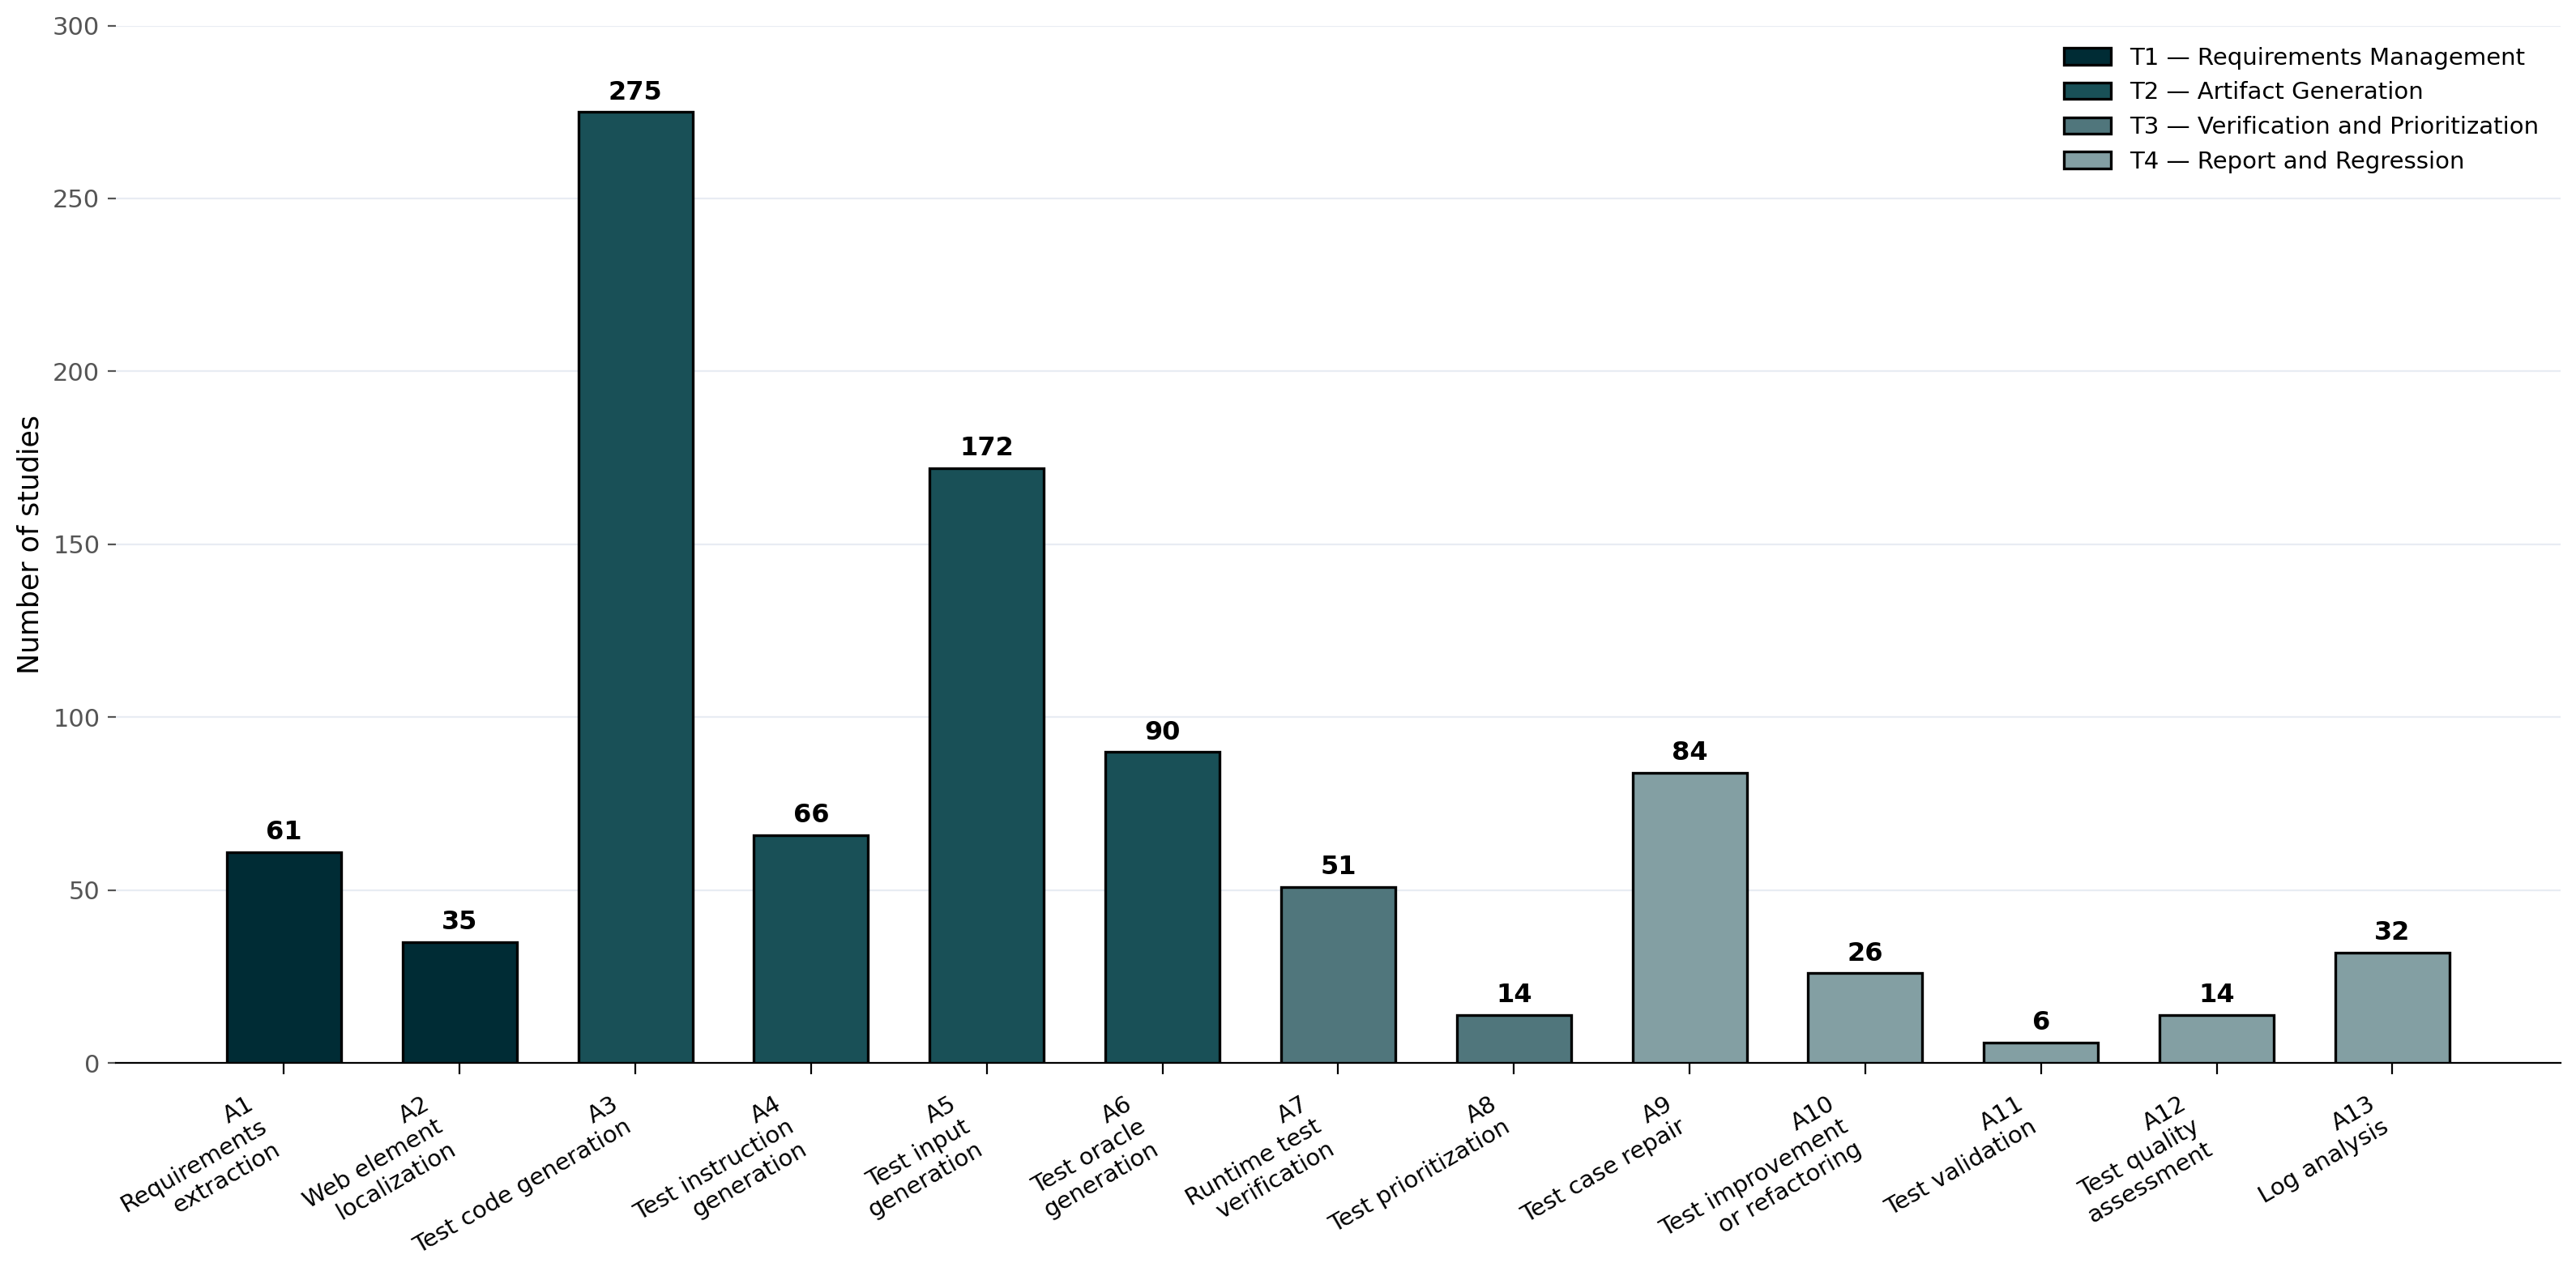

In [3]:
fig, ax = plt.subplots(figsize=(16, 8), dpi=200)

for x, d in zip(x_pos, dados):
    ax.bar(x, d["valor"], color=d["cor"], width=0.65, edgecolor="black", linewidth=1.2, zorder=3)
    ax.text(
        x, d["valor"] + 2, str(d["valor"]),
        ha="center", va="bottom", fontsize=11.5, fontweight="bold", color="black",
    )

ax.set_xticks(list(x_pos))
ax.set_xticklabels([d["tipo"] for d in dados], rotation=30, ha="right", fontsize=10.5)

ax.set_ylim(0, 300)
ax.set_ylabel("Number of studies", fontsize=12.5)

for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color("black")
ax.tick_params(axis="x", length=5, pad=8, color="black")
ax.tick_params(axis="y", colors="#555555", labelsize=11)
ax.yaxis.grid(True, color="#e8ecf3", zorder=0)
ax.set_axisbelow(True)

legend_handles = [
    Patch(facecolor=cores_estagio[s], edgecolor="black", linewidth=1.2, label=f"T{s} — {STAGE_NAMES[s]}")
    for s in STAGE_ORDER
]
ax.legend(handles=legend_handles, loc="upper right", frameon=False, fontsize=10.5)

plt.tight_layout()
plt.savefig("atividades_por_estagio.png", bbox_inches="tight", dpi=200)
plt.show()